# 第7讲 机器学习基础与朴素贝叶斯 辅助实验
核心学习与答案写在Word worksheet。Notebook只供重现和核对；不需要从零编程。按已发Packet执行，不要提前运行D；完整执行仅供教师复现。全部数据离线可用，禁止临床应用。

In [1]:
from pathlib import Path
import sys, json, itertools
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import confusion_matrix, log_loss, mean_squared_error, roc_auc_score, precision_recall_curve, average_precision_score, auc, brier_score_loss
root = Path.cwd().resolve()
if root.name == 'notebook': root = root.parent
assert (root/'assets').exists(), '请从本课目录或notebook目录运行'
assets = root/'assets/pbl-machine-learning-basics-naive-bayes'
df = pd.read_csv(assets/'acute-inflammations.csv')
print('Python:', sys.executable)
print(df.shape)
display(df.head())

Python: D:\Python\python.exe
(120, 8)


,temperature_c,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


## Packet A Q1 记录与表示
一行不是已确认独立患者。核对层级、缺失、重复与连续/二值表示；不要静默去重。

In [2]:
assert df.shape == (120,8)
assert df.isna().sum().sum() == 0
display(df.describe(include='all'))
print('全行重复余量:', df.duplicated().sum(), '重复组总行:', df.duplicated(keep=False).sum())
print('原始输入组合:', df.iloc[:,:6].drop_duplicates().shape[0])
X = np.column_stack([(df.iloc[:,0]>=38).astype(int), *(df[c].eq('yes').astype(int) for c in df.columns[1:6])])
y = df['bladder_inflammation'].eq('yes').to_numpy(dtype=int)
print('二值组合:', np.unique(X,axis=0).shape[0], '类别计数:', np.bincount(y))

,temperature_c,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
count,120.000000,120,120,120,120,120,120,120
unique,NaN,2,2,2,2,2,2,2
top,NaN,no,yes,yes,no,no,no,no
freq,NaN,91,70,80,61,70,61,70
mean,38.724167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.819132,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,35.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,37.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,37.950000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,40.600000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


全行重复余量: 21 重复组总行: 40
原始输入组合: 99
二值组合: 9 类别计数: [61 59]


## Q2 固定数据职责
先保留20%测试，再从剩余80%中取25%为验证，总比例60/20/20。不根据分数换种子。

In [3]:
dev, te = train_test_split(np.arange(len(y)), test_size=.2, random_state=7, stratify=y)
tr, va = train_test_split(dev, test_size=.25, random_state=7, stratify=y[dev])
assert not (set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
for name, ix in [('训练',tr),('验证',va),('测试',te)]: print(name, len(ix), np.bincount(y[ix]))
saved=pd.read_csv(assets/'split-indices.csv')
for label,ix in [('tr',tr),('va',va),('te',te)]: assert saved.loc[saved.split==label,'source_row'].tolist()==(ix+1).tolist()

训练 72 [37 35]
验证 24 [12 12]
测试 24 [12 12]


## Packet B Q3 用计数训练
模型估计每类中各症状为1的概率，加一平滑；0症状使用补概率。先手算worksheet查询1，再运行核对。

In [4]:
counts=np.array([X[tr][y[tr]==c].sum(axis=0) for c in [0,1]])
n=np.bincount(y[tr]); theta=(counts+1)/(n[:,None]+2); priors=n/n.sum()
model=BernoulliNB(alpha=1).fit(X[tr],y[tr])
assert np.allclose(theta,np.exp(model.feature_log_prob_))
q=np.array([0,0,0,1,1,0])
factors=np.where(q,theta,1-theta)
scores=priors*factors.prod(axis=1); post=scores/scores.sum()
print('counts',counts,'theta',theta,'priors',priors,sep='\n')
print('因子',factors,'类别分数',scores,'后验',post,sep='\n')
assert np.allclose(post,model.predict_proba([q])[0])
saved_counts=pd.read_csv(assets/'packet-b1.csv'); assert np.array_equal(saved_counts.iloc[:,1:].to_numpy(),counts[[1,0]].T)

counts
[[25  5 30 13  5 13]
 [13 13 13 35 28 17]]
theta
[[0.66666667 0.15384615 0.79487179 0.35897436 0.15384615 0.35897436]
 [0.37837838 0.37837838 0.37837838 0.97297297 0.78378378 0.48648649]]
priors
[0.51388889 0.48611111]
因子
[[0.33333333 0.84615385 0.20512821 0.35897436 0.15384615 0.64102564]
 [0.62162162 0.62162162 0.62162162 0.97297297 0.78378378 0.51351351]]
类别分数
[0.00105256 0.04572596]
后验
[0.02250099 0.97749901]


反思：为什么查询中0值的症状仍要参与乘积？若把关键词出现改成频次，这个式子改变了什么？

## Q4 两种损失
以下是明确给定输入的合成教学例，不是额外患者。

In [5]:
toy_y=np.array([1,0,1,0]); pa=np.array([.8,.2,.4,.1]); pb=np.array([.99,.01,.01,.01])
for name,p in [('甲',pa),('乙',pb)]:
    per=-(toy_y*np.log(p)+(1-toy_y)*np.log(1-p))
    print(name,'逐例损失',per,'平均',per.mean(),'accuracy',((p>=.5)==toy_y).mean())
    assert np.isclose(per.mean(),log_loss(toy_y,p))
print('MSE',mean_squared_error([37,39],[38,37]),'℃²')
assert mean_squared_error([37,39],[38,37])==2.5

甲 逐例损失 [0.22314355 0.22314355 0.91629073 0.10536052] 平均 0.3669845875401002 accuracy 0.75
乙 逐例损失 [0.01005034 0.01005034 4.60517019 0.01005034] 平均 1.1588302983871488 accuracy 0.75
MSE 2.5 ℃²


## Packet C Q5 分类、排序与概率
所有选阈值动作只使用验证；先写冻结配置再运行D。

In [6]:
p=model.predict_proba(X[va])[:,1]
rows=[]
for threshold in [.1,.5,.9]:
    tn,fp,fn,tp=confusion_matrix(y[va],p>=threshold,labels=[0,1]).ravel()
    rows.append([threshold,tn,fp,fn,tp,(tp+tn)/len(va),tp/(tp+fn),tn/(tn+fp),tp/(tp+fp),2*tp/(2*tp+fp+fn)])
metric_table=pd.DataFrame(rows,columns=['threshold','TN','FP','FN','TP','accuracy','sensitivity','specificity','precision','F1'])
display(metric_table)
assert np.array_equal(metric_table.iloc[:3,1:5].to_numpy(),pd.read_csv(assets/'packet-c1.csv').iloc[:3,1:].to_numpy())
print('先验基线precision分母为0：未定义；recall=0。')

,threshold,TN,FP,FN,TP,accuracy,sensitivity,specificity,precision,F1
0,0.1,7,5,0,12,0.791667,1.000000,0.583333,0.705882,0.827586
1,0.5,12,0,0,12,1.000000,1.000000,1.000000,1.000000,1.000000
2,0.9,12,0,2,10,0.916667,0.833333,1.000000,1.000000,0.909091


先验基线precision分母为0：未定义；recall=0。


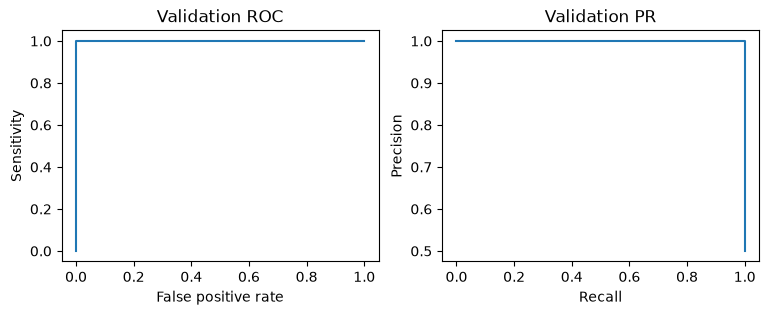

original ROC 1.0 PR trapezoid 1.0 AP 1.0 logloss 0.08721381083393166
0.25+0.50p ROC 1.0 PR trapezoid 1.0 AP 1.0 logloss 0.34415103925551166
Optional illustration: AP 0.8333333333333333 PR trapezoid 0.7916666666666666


In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
fpr,tpr,_=roc_curve(y[va],p); precision,recall,_=precision_recall_curve(y[va],p)
fig,ax=plt.subplots(1,2,figsize=(9,3))
ax[0].plot(fpr,tpr);ax[0].set(xlabel='False positive rate',ylabel='Sensitivity',title='Validation ROC')
ax[1].plot(recall,precision);ax[1].set(xlabel='Recall',ylabel='Precision',title='Validation PR');plt.show()
for name,prob in [('original',p),('0.25+0.50p',.25+.5*p)]:
    pp,rr,_=precision_recall_curve(y[va],prob)
    print(name, 'ROC',roc_auc_score(y[va],prob),'PR trapezoid',auc(rr,pp),'AP',average_precision_score(y[va],prob),'logloss',log_loss(y[va],prob))
# 非完美排序支持例，说明AP与梯形PR面积一般不等
pp,rr,_=precision_recall_curve([1,0,1,0],[.9,.8,.7,.1])
print('Optional illustration: AP',average_precision_score([1,0,1,0],[.9,.8,.7,.1]),'PR trapezoid',auc(rr,pp))

In [8]:
cal=[]
for lo,hi in [(0,.1),(.1,.5),(.5,.9),(.9,1)]:
    mask=(p>=lo)&((p<hi) if hi<1 else (p<=hi))
    if mask.sum(): cal.append([lo,hi,int(mask.sum()),int(y[va][mask].sum()),p[mask].mean(),y[va][mask].mean()])
cal=pd.DataFrame(cal,columns=['lower','upper','n','positive','mean_p','observed_rate']);display(cal)
saved_cal=pd.read_csv(assets/'packet-c3.csv')
assert np.allclose(cal.iloc[:,2:].to_numpy(),saved_cal.iloc[:,1:].to_numpy(),atol=5e-5)
print('Brier',brier_score_loss(y[va],p),'（不是纯校准误差）')

,lower,upper,n,positive,mean_p,observed_rate
0,0.0,0.1,7,0,0.045558,0.0
1,0.1,0.5,5,0,0.149824,0.0
2,0.5,0.9,2,2,0.779846,1.0
3,0.9,1.0,10,10,0.957881,1.0


Brier 0.011766036393776921 （不是纯校准误差）


反思：什么性质被单调变换保留？每箱人数怎样限制校准结论？

## Packet D Q6 条件独立与复制输入
此处仅在D解封后运行。64种穷举向量不等于64患者。

In [9]:
joint=[]
for c in [1,0]:
    for a,b in itertools.product([0,1],repeat=2):
        joint.append([c,a,b,int(((y[tr]==c)&(X[tr,3]==a)&(X[tr,4]==b)).sum())])
display(pd.DataFrame(joint,columns=['class','urine','pain','n']))
assert np.array_equal(np.array(joint),pd.read_csv(assets/'packet-d1.csv').values)
grid=np.array(list(itertools.product([0,1],repeat=6)))
dup=BernoulliNB(alpha=1).fit(np.column_stack([X[tr],X[tr,1]]),y[tr])
pg=model.predict_proba(grid)[:,1];pdg=dup.predict_proba(np.column_stack([grid,grid[:,1]]))[:,1]
print('类别改变',((pg>=.5)!=(pdg>=.5)).sum(),'最大概率差',abs(pg-pdg).max())
assert np.allclose(np.column_stack([grid,pg,pdg]),pd.read_csv(assets/'redundancy-all64.csv').to_numpy())

,class,urine,pain,n
0,1,0,0,0
1,1,0,1,0
2,1,1,0,7
3,1,1,1,28
4,0,0,0,19
5,0,0,1,5
6,0,1,0,13
7,0,1,1,0


类别改变 5 最大概率差 0.221082487429704


In [10]:
testp=model.predict_proba(X[te])[:,1]
print('固定测试',confusion_matrix(y[te],testp>=.5,labels=[0,1]),'log loss',log_loss(y[te],testp))
train_patterns=set(map(tuple,X[tr]));raw=df.iloc[:,:6].astype(str).to_numpy();raw_train=set(map(tuple,raw[tr]))
for name,ix in [('validation',va),('test',te)]:
    print(name,'binary patterns',len(set(map(tuple,X[ix]))),'seen',sum(tuple(v) in train_patterns for v in X[ix]),'raw seen',sum(tuple(v) in raw_train for v in raw[ix]))
assert np.array_equal(confusion_matrix(y[te],testp>=.5),[[12,0],[0,12]])
TP,FN,FP,TN=95,5,495,9405
print('假设低患病率precision',TP/(TP+FP),'accuracy',(TP+TN)/10000,'all negative accuracy',.99)

固定测试 [[12  0]
 [ 0 12]] log loss 0.07449229980495913
validation binary patterns 9 seen 24 raw seen 2
test binary patterns 8 seen 24 raw seen 6
假设低患病率precision 0.16101694915254236 accuracy 0.95 all negative accuracy 0.99


## 翻转课堂 二症状训练复现
仍从训练72条拟合，仅保留尿意频繁与排尿痛；验证24条按人数加权。

In [11]:
two=BernoulliNB(alpha=1).fit(X[tr][:,[3,4]],y[tr])
classroom=pd.read_csv(assets/'packet-b3.csv')
classroom['posterior']=two.predict_proba(classroom.iloc[:,:2].to_numpy())[:,1]
classroom['prediction']=(classroom['posterior']>=.5).astype(int);display(classroom)
cm=confusion_matrix(y[va],two.predict(X[va][:,[3,4]]),labels=[0,1]); print(cm)
weighted=np.zeros((2,2),dtype=int)
for row in classroom.itertuples(index=False,name=None): weighted[int(row[2]),int(row[5])]+=int(row[3])
assert np.array_equal(cm,weighted)
tn,fp,fn,tp=cm.ravel();print('sensitivity',tp/(tp+fn),'specificity',tn/(tn+fp))
print('核心复现检查全部通过。')

,尿意频繁,排尿痛,真实标签,记录数,posterior,prediction
0,0,0,0,4,0.010088,0
1,0,1,0,3,0.168875,0
2,1,0,0,5,0.395826,0
3,1,0,1,1,0.395826,0
4,1,1,1,11,0.928887,1


[[12  0]
 [ 1 11]]
sensitivity 0.9166666666666666 specificity 1.0
核心复现检查全部通过。


最终反思：把任务、数据职责、训练、损失、分类/排序/校准和假设写进同一研究备忘录。选择A、B、C都需证据；不要把固定教学测试当成真实部署证据。